# Movie Recommendation System
## Machine Learning Individual Project
Third Year - Computer Science and Engineering

This notebook documents the machine learning workflow of the project.

## 1. Import Libraries

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Dataset Loading

In [16]:
df = pd.read_csv("../Dataset/selected_movies.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (47, 6)


,movie_id,title,genre,description,language,content
0,1,Avatar,Sci-Fi,An alien world filled with action and adventure,English,Sci-Fi An alien world filled with action and a...
1,3,The Avengers,Action,Superheroes unite to save the world,English,Action Superheroes unite to save the world
2,4,Interstellar,Sci-Fi,A journey through space and time,English,Sci-Fi A journey through space and time
3,5,The Imitation Game,Drama,A mathematician works to solve a complex warti...,English,Drama A mathematician works to solve a complex...
4,6,Iron Man,Action,A genius builds a powerful suit,English,Action A genius builds a powerful suit


## 3. Data Information and Preprocessing

In [17]:
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 47 entries, 0 to 46
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   movie_id     47 non-null     int64
 1   title        47 non-null     str  
 2   genre        47 non-null     str  
 3   description  47 non-null     str  
 4   language     47 non-null     str  
 5   content      47 non-null     str  
dtypes: int64(1), str(5)
memory usage: 7.6 KB

Missing values:
movie_id       0
title          0
genre          0
description    0
language       0
content        0
dtype: int64

Duplicate rows: 0


## 4. Exploratory Data Analysis

genre
Action              7
Drama               6
Animation           6
Comedy              6
Sci-Fi              5
Horror              3
Adventure           2
Fantasy             2
Romance             2
Mystery             2
Biography           2
Historical          1
Thriller            1
Sports              1
Historical Drama    1
Name: count, dtype: int64


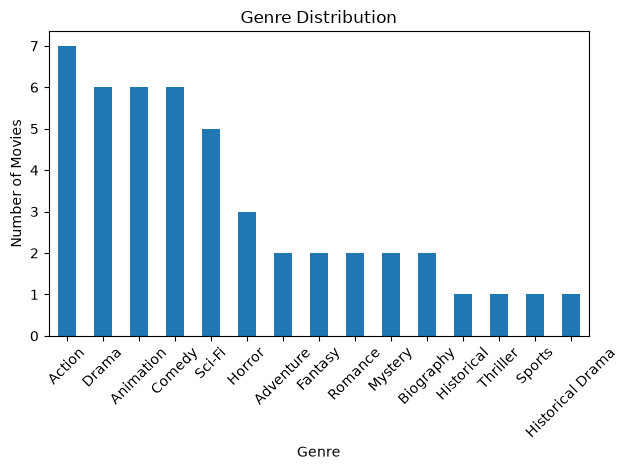

In [18]:
print(df["genre"].value_counts())

df["genre"].value_counts().plot(
    kind="bar",
    title="Genre Distribution"
)

plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. Feature Selection

In [19]:
X = df["content"].fillna("")

print("Selected feature: content (genre + description)")
print("Total records:", len(X))

Selected feature: content (genre + description)
Total records: 47


## 6. Train-Test Split

In [20]:
X_train, X_test = train_test_split(
    X, test_size=0.2, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 37
Testing records: 10


## 7. Algorithm Comparison

In [21]:
count_vectorizer = CountVectorizer(stop_words="english")
count_matrix = count_vectorizer.fit_transform(X)

tfidf_vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf_vectorizer.fit_transform(X)

print("CountVectorizer shape:", count_matrix.shape)
print("TF-IDF shape:", tfidf_matrix.shape)

CountVectorizer shape: (47, 158)
TF-IDF shape: (47, 158)


## 8. Model Improvement Experiments

In [22]:
results = pd.read_csv("../Documentation/model_improvement_results.csv")
display(results)

,Experiment,Average Similarity,Genre Match (%),Coverage (%)
0,Default,0.3453,56.0,78.38
1,Unigrams + Bigrams,0.2679,56.0,78.38
2,Minimum Document Frequency 2,0.5411,58.0,67.57


## 9. Final Model and Recommendation

In [23]:
similarity = cosine_similarity(count_matrix)

def recommend_movie(movie_title, number=5):
    matches = df.index[
        df["title"].str.lower() == movie_title.lower()
    ].tolist()

    if not matches:
        print("Movie not found.")
        return

    index = matches[0]
    scores = sorted(
        enumerate(similarity[index]),
        key=lambda item: item[1],
        reverse=True
    )

    for i, score in scores[1:number+1]:
        print(df.iloc[i]["title"], "-", round(score, 3))

recommend_movie("Interstellar")

Gravity - 0.548
The Matrix - 0.365
Avatar - 0.338
Inception - 0.338
The Secret Life of Mitty - 0.2


## 10. Conclusion

This project uses content-based movie recommendation.
CountVectorizer converts movie descriptions and genres into
numerical features. Cosine similarity identifies similar movies.

The project compares CountVectorizer and TF-IDF.
Evaluation values are proxy measures because the dataset
does not contain user ratings or relevance labels.